In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
# load the dataset
df = pd.read_csv("music_mood_dataset.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nOriginal Mood Distribution:")
print(df['Mood'].value_counts())

Dataset Shape: (586672, 10)

First 5 Rows:


,name,artists,danceability,energy,loudness,acousticness,instrumentalness,valence,tempo,Mood
0,Carve,['Uli'],0.645,0.4450,-13.338,0.674,0.7440,0.127,104.851,Calm
1,Capítulo 2.16 - Banquero Anarquista,['Fernando Pessoa'],0.695,0.2630,-22.136,0.797,0.0000,0.655,102.009,Happy
2,Vivo para Quererte - Remasterizado,['Ignacio Corsini'],0.434,0.1770,-21.180,0.994,0.0218,0.457,130.418,Sad
3,El Prisionero - Remasterizado,['Ignacio Corsini'],0.321,0.0946,-27.961,0.995,0.9180,0.397,169.980,Calm
4,Lady of the Evening,['Dick Haymes'],0.402,0.1580,-16.900,0.989,0.1300,0.196,103.220,Sad



Original Mood Distribution:
Mood
Sad          212113
Energetic    180274
Happy        152960
Calm          41325
Name: count, dtype: int64


In [ ]:
# remove rows with missing values
print("Missing values before removal:")
print(df.isnull().sum())

df = df.dropna()

print("\nMissing values after removal:")
print(df.isnull().sum())
print("\nRemaining rows:", df.shape[0])

Missing values before removal:
name                71
artists              0
danceability         0
energy               0
loudness             0
acousticness         0
instrumentalness     0
valence              0
tempo                0
Mood                 0
dtype: int64

Missing values after removal:
name                0
artists             0
danceability        0
energy              0
loudness            0
acousticness        0
instrumentalness    0
valence             0
tempo               0
Mood                0
dtype: int64

Remaining rows: 586601


In [ ]:
# balance the dataset by downsampling the majority classes
min_class_size = df['Mood'].value_counts().min()
print(f"Smallest class size: {min_class_size}")

df_balanced = (
    df.groupby('Mood', group_keys=False)
      .sample(n=min_class_size, random_state=42)
      .reset_index(drop=True)
)

print("\nBalanced class distribution:")
print(df_balanced['Mood'].value_counts().to_string())
print("\nTotal number of data (balanced):", df_balanced.shape[0])

Smallest class size: 41299

Balanced class distribution:
Mood
Calm         41299
Energetic    41299
Happy        41299
Sad          41299

Total number of data (balanced): 165196


In [ ]:
# Encode the 'Mood' column
label_encoder = LabelEncoder()
df_balanced['Mood_encoded'] = label_encoder.fit_transform(df_balanced['Mood'])

class_mapping = dict(zip(label_encoder.classes_, range(len(label_encoder.classes_))))
print("Class Mapping Dictionary:", class_mapping)
print("\nSample Encoded Values:")
print(df_balanced[['Mood', 'Mood_encoded']].head(10))

Class Mapping Dictionary: {'Calm': 0, 'Energetic': 1, 'Happy': 2, 'Sad': 3}

Sample Encoded Values:
   Mood  Mood_encoded
0  Calm             0
1  Calm             0
2  Calm             0
3  Calm             0
4  Calm             0
5  Calm             0
6  Calm             0
7  Calm             0
8  Calm             0
9  Calm             0


In [ ]:
# Split the dataset into training and testing sets
feature_cols = [
    'danceability', 'energy', 'loudness',
    'acousticness', 'instrumentalness', 'valence', 'tempo'
]

X = df_balanced[feature_cols]
y = df_balanced['Mood_encoded']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Set Shape:", X_train_scaled.shape)
print("Testing Set Shape :", X_test_scaled.shape)
print("Training class distribution:", np.bincount(y_train).tolist())
print("Testing class distribution :", np.bincount(y_test).tolist())

Training Set Shape: (132156, 7)
Testing Set Shape : (33040, 7)
Training class distribution: [33039, 33039, 33039, 33039]
Testing class distribution : [8260, 8260, 8260, 8260]


C:\Users\User\AppData\Local\Temp\ipykernel_3272\2985939918.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_balanced, x='Mood', palette='magma')


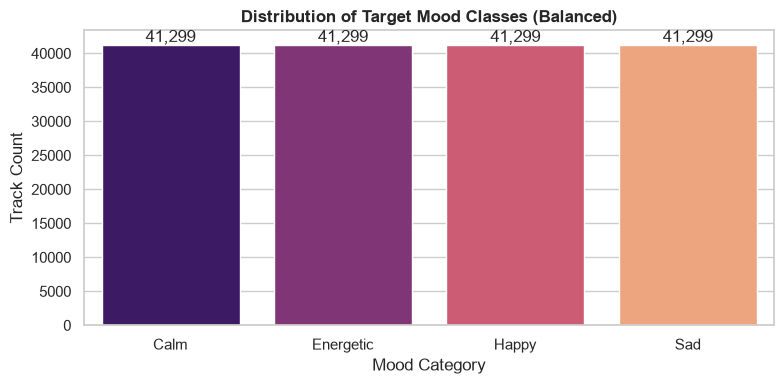

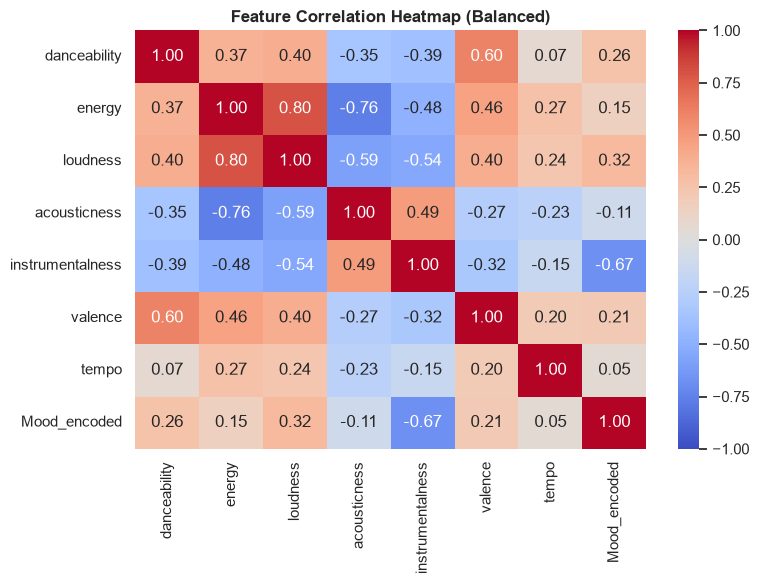

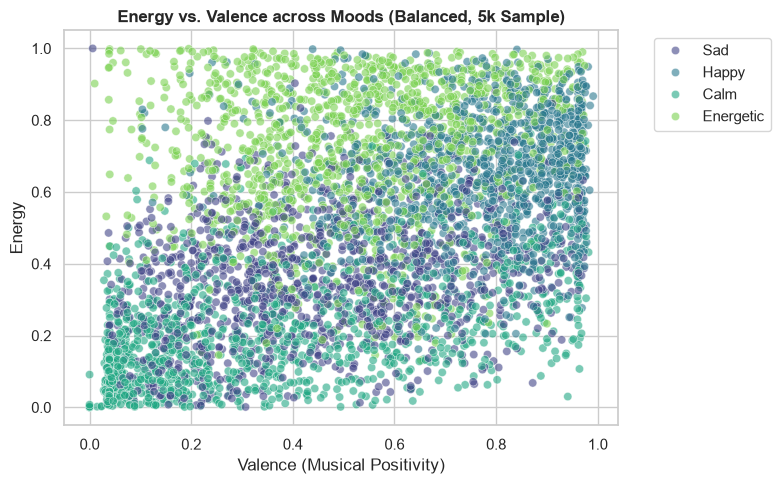

C:\Users\User\AppData\Local\Temp\ipykernel_3272\2985939918.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_balanced, x='Mood', y='danceability', palette='Set2')


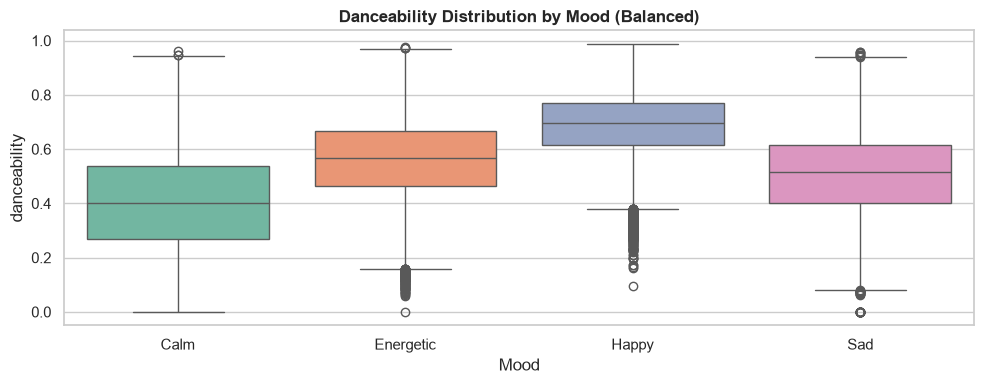

In [ ]:
# Visualizations
sns.set_theme(style="whitegrid", palette="muted")

# Distribution of Target Mood Classes (Balanced)
plt.figure(figsize=(8, 4))
ax = sns.countplot(data=df_balanced, x='Mood', palette='magma')
plt.title('Distribution of Target Mood Classes (Balanced)', fontweight='bold', fontsize=12)
plt.xlabel('Mood Category')
plt.ylabel('Track Count')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.tight_layout()
plt.show()

# Correlation Heatmap of Features (Balanced)
plt.figure(figsize=(8, 6))
numeric_df = df_balanced.select_dtypes(include=['number'])
corr_matrix = numeric_df.corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, cbar=True)
plt.title('Feature Correlation Heatmap (Balanced)', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

# Scatter Plot of Energy vs. Valence colored by Mood (Balanced)
plt.figure(figsize=(8, 5))
sample_df = df_balanced.sample(n=min(5000, len(df_balanced)), random_state=42)
sns.scatterplot(data=sample_df, x='valence', y='energy', hue='Mood', alpha=0.6, palette='viridis')
plt.title('Energy vs. Valence across Moods (Balanced, 5k Sample)', fontweight='bold', fontsize=12)
plt.xlabel('Valence (Musical Positivity)')
plt.ylabel('Energy')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Boxplot of Danceability by Mood (Balanced)
plt.figure(figsize=(10, 4))
sns.boxplot(data=df_balanced, x='Mood', y='danceability', palette='Set2')
plt.title('Danceability Distribution by Mood (Balanced)', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
# Train a Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42)
rf_model.fit(X_train_scaled, y_train)

y_train_pred = rf_model.predict(X_train_scaled)
y_val_pred = rf_model.predict(X_test_scaled)

train_acc = accuracy_score(y_train, y_train_pred)
val_acc = accuracy_score(y_test, y_val_pred)

print(f"Training Accuracy   : {train_acc * 100:.2f}%")
print(f"Validation Accuracy : {val_acc * 100:.2f}%")

Training Accuracy   : 93.70%
Validation Accuracy : 90.81%


C:\Users\User\AppData\Local\Temp\ipykernel_3272\4258100077.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df, x='Importance', y='Feature', palette='Blues_r')


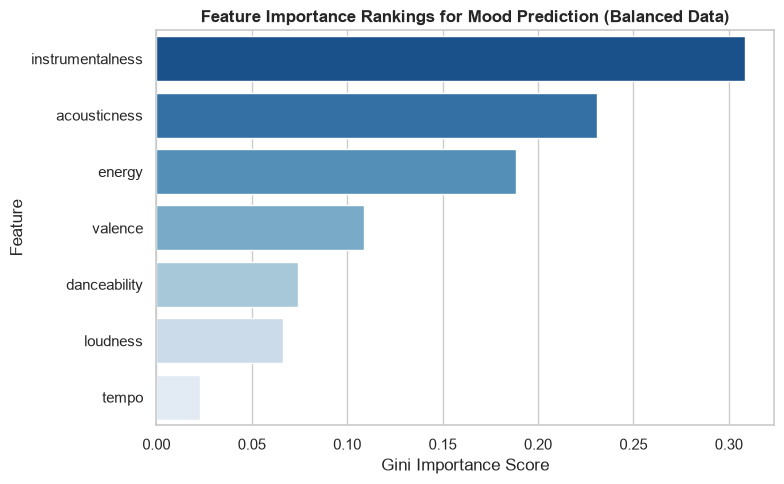

In [ ]:
# Feature Importance
importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=importance_df, x='Importance', y='Feature', palette='Blues_r')
plt.title('Feature Importance Rankings for Mood Prediction (Balanced Data)', fontweight='bold')
plt.xlabel('Gini Importance Score')
plt.tight_layout()
plt.show()

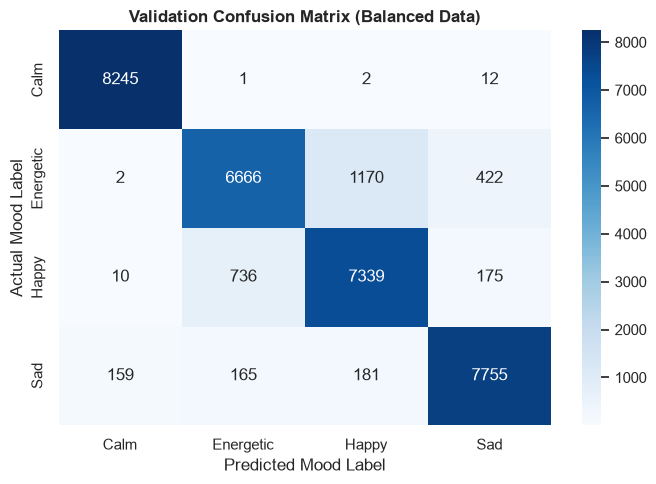


=== DETAILED CLASSIFICATION REPORT (BALANCED) ===
              precision    recall  f1-score   support

        Calm       0.98      1.00      0.99      8260
   Energetic       0.88      0.81      0.84      8260
       Happy       0.84      0.89      0.87      8260
         Sad       0.93      0.94      0.93      8260

    accuracy                           0.91     33040
   macro avg       0.91      0.91      0.91     33040
weighted avg       0.91      0.91      0.91     33040



In [ ]:
# Confusion Matrix and Classification Report
cm = confusion_matrix(y_test, y_val_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Validation Confusion Matrix (Balanced Data)', fontweight='bold')
plt.xlabel('Predicted Mood Label')
plt.ylabel('Actual Mood Label')
plt.tight_layout()
plt.show()

print("\n=== DETAILED CLASSIFICATION REPORT (BALANCED) ===")
print(classification_report(y_test, y_val_pred, target_names=label_encoder.classes_))

In [ ]:
# sample predictions table
target_positive = 'Happy'

predicted_labels = label_encoder.inverse_transform(y_val_pred)
actual_labels = label_encoder.inverse_transform(y_test)

song_names = df_balanced.loc[X_test.index, 'name'].values

sample_df = pd.DataFrame({
    'Song Name': song_names,
    'Ground Truth (Actual)': actual_labels,
    'Predicted Label': predicted_labels
})

def get_result_type(row):
    actual = row['Ground Truth (Actual)']
    pred = row['Predicted Label']

    if actual == target_positive and pred == target_positive:
        return 'TP'
    elif actual != target_positive and pred != target_positive:
        return 'TN'
    elif actual != target_positive and pred == target_positive:
        return 'FP'
    elif actual == target_positive and pred != target_positive:
        return 'FN'

sample_df['Result'] = sample_df.apply(get_result_type, axis=1)

html_table = sample_df.head(20).to_html(index=False, classes='table table-striped')
display(HTML(f"<h3>Sample Predictions (n=20) | Positive Class = '{target_positive}'</h3>" + html_table))

Song Name,Ground Truth (Actual),Predicted Label,Result
Basin Street Blues (Live),Calm,Calm,TN
Mashed Potato Popcorn (Part 1),Happy,Happy,TP
Lakh Khushian Patshahian,Energetic,Happy,FP
I'm Gonna Make Her Love Me,Energetic,Energetic,TN
Progress,Energetic,Energetic,TN
Секрет,Sad,Sad,TN
Kapitel 09 - Der rote Hahn (Folge 015),Energetic,Energetic,TN
Damned,Calm,Calm,TN
"Let's Get Together - From ""The Parent Trap""",Happy,Happy,TP
Sueños Rotos,Happy,Happy,TP
